# Home Credit Default Risk — Modeling

This notebook establishes an imbalanced-class benchmark and compares a small set of candidate models. All reusable data loading, preprocessing, resampling, and cross-validation logic lives in `src/models/modeling.py`; the notebook only orchestrates and communicates the analysis.

## Setup

Import the project utilities and modeling libraries. The project root is added to the Python path so the notebook can be run from either the repository root or the `notebooks/` directory.

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit, cross_validate

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.modeling import RANDOM_STATE, compare_models, load_prepared_data

warnings.filterwarnings('ignore', category=UserWarning, module='lightgbm')
plt.style.use('seaborn-v0_8-whitegrid')

Load the prepared application-level data. `load_prepared_data()` explicitly excludes `SK_ID_CURR` from predictors while retaining test IDs for a later submission.

In [2]:
X, y, X_test, test_ids = load_prepared_data()

pd.DataFrame({
    'rows': [len(X), len(X_test)],
    'predictors': [X.shape[1], X_test.shape[1]],
}, index=['train', 'test']).rename_axis('split')

,rows,predictors
split,,
train,307507,177
test,48744,177


## 1. Benchmark: the majority-class model

A model that always predicts the non-default class is the minimum meaningful benchmark. It needs no predictors; using a one-column placeholder prevents unnecessary preprocessing and makes the benchmark nearly instantaneous.

Evaluate the majority classifier with the same three-fold stratified splits used later. Report both accuracy and ROC AUC so the class-imbalance effect is visible.

In [3]:
benchmark_folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
benchmark = cross_validate(
    DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    np.zeros((len(y), 1)),
    y,
    cv=benchmark_folds,
    scoring={'auc': 'roc_auc', 'accuracy': 'accuracy'},
    n_jobs=-1,
)

benchmark_results = pd.DataFrame({
    'model': ['Majority class'],
    'mean_auc': [benchmark['test_auc'].mean()],
    'mean_accuracy': [benchmark['test_accuracy'].mean()],
})
benchmark_results.style.format({'mean_auc': '{:.3f}', 'mean_accuracy': '{:.3f}'})

,model,mean_auc,mean_accuracy
0,Majority class,0.500,0.919


With roughly 8% defaults, predicting every applicant as non-default is correct about 92% of the time, yet it assigns every applicant the same score and therefore has AUC 0.50. Accuracy rewards the dominant class and cannot distinguish useful risk ranking from this no-skill baseline. ROC AUC is the primary comparison metric because it evaluates how well a model ranks default risk across thresholds.

## 2. Candidate models

To keep this exploratory comparison practical, draw a reproducible 50,000-row stratified sample. This preserves the observed default rate while making three-fold evaluation of all four models manageable.

Create the development sample and define a small, interpretable predictor set. The small logistic model tests the value of the external-source scores plus core application characteristics against models using the full prepared feature set.

In [4]:
sample_split = StratifiedShuffleSplit(n_splits=1, train_size=50_000, random_state=RANDOM_STATE)
sample_indices, _ = next(sample_split.split(X, y))
X_sample = X.iloc[sample_indices].copy()
y_sample = y.iloc[sample_indices].copy()

small_predictors = [
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY',
    'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CODE_GENDER',
    'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
]
missing_predictors = sorted(set(small_predictors).difference(X_sample.columns))
if missing_predictors:
    raise KeyError(f'Missing expected small-set predictors: {missing_predictors}')
X_small = X_sample.loc[:, small_predictors]

pd.DataFrame({
    'default_rate': [y.mean(), y_sample.mean()],
    'rows': [len(y), len(y_sample)],
}, index=['full training data', 'stratified sample']).style.format({'default_rate': '{:.2%}', 'rows': '{:,.0f}'})

,default_rate,rows
full training data,8.07%,"307,507"
stratified sample,8.07%,"50,000"


Plot the outcome mix in the development sample. Its close match to the full training rate is the visual check that stratified sampling retained the rare-event structure.

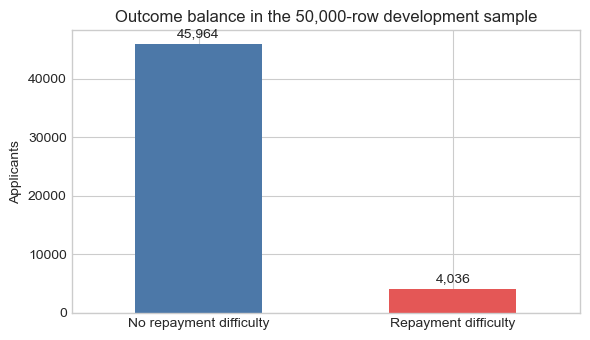

In [5]:
outcome_labels = y_sample.map({0: 'No repayment difficulty', 1: 'Repayment difficulty'})
ax = outcome_labels.value_counts().reindex(['No repayment difficulty', 'Repayment difficulty']).plot(
    kind='bar', color=['#4C78A8', '#E45756'], figsize=(6, 3.5), rot=0
)
ax.set(title='Outcome balance in the 50,000-row development sample', xlabel='', ylabel='Applicants')
for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)
plt.tight_layout()
plt.show()

Fit and evaluate the candidate models. `compare_models()` constructs its preprocessing pipeline inside each cross-validation fold. Random forest and LightGBM each use `n_jobs=1`, while the reusable comparison function parallelizes across folds; this avoids nested parallelism and noisy training output.

In [6]:
small_logistic = LogisticRegression(
    max_iter=1_000, solver='liblinear', random_state=RANDOM_STATE
)
full_logistic = LogisticRegression(
    max_iter=1_000, solver='liblinear', random_state=RANDOM_STATE
)
random_forest = RandomForestClassifier(
    n_estimators=200, min_samples_leaf=20,
    n_jobs=1, random_state=RANDOM_STATE
)
lightgbm = LGBMClassifier(
    n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
    colsample_bytree=0.8, n_jobs=1, random_state=RANDOM_STATE, verbosity=-1
)

small_results = compare_models({'Logistic regression (small set)': small_logistic}, X_small, y_sample)
full_results = compare_models(
    {
        'Logistic regression (all predictors)': full_logistic,
        'Random forest': random_forest,
        'LightGBM': lightgbm,
    },
    X_sample,
    y_sample,
)
comparison_results = pd.concat([small_results, full_results], ignore_index=True).sort_values(
    'mean_auc', ascending=False, ignore_index=True
)
comparison_results.style.format({
    'mean_auc': '{:.4f}', 'std_auc': '{:.4f}', 'mean_accuracy': '{:.4f}'
})

,model,mean_auc,std_auc,mean_accuracy
0,LightGBM,0.7433,0.0084,0.9194
1,Logistic regression (all predictors),0.7416,0.0082,0.9189
2,Random forest,0.7371,0.0103,0.9193
3,Logistic regression (small set),0.7308,0.0076,0.9191


**LightGBM is the best candidate** on this 50,000-row development sample, with mean ROC AUC **0.7433** (standard deviation 0.0084). It leads all-predictor logistic regression by **0.0017** AUC, random forest by **0.0062**, and the compact logistic model by **0.0125**. All four models materially beat the 0.50 no-skill benchmark: their AUC gains are **0.2433** for LightGBM, **0.2416** for all-predictor logistic regression, **0.2371** for random forest, and **0.2308** for the compact logistic model. Their similar ~0.919 accuracy should not drive selection: the majority-class benchmark reaches about 0.92 accuracy while providing no risk ranking at all.

Visualize the AUC comparison to make the ranking and fold-to-fold variation easier to scan than the table alone.

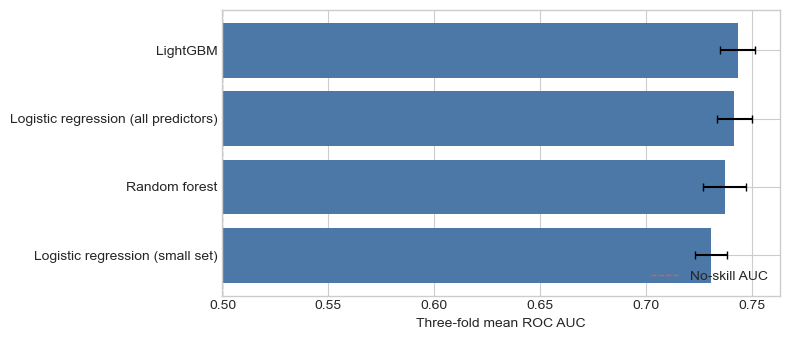

In [7]:
plot_results = comparison_results.sort_values('mean_auc')
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(plot_results['model'], plot_results['mean_auc'], xerr=plot_results['std_auc'], color='#4C78A8', capsize=3)
ax.axvline(0.50, color='#E45756', linestyle='--', linewidth=1, label='No-skill AUC')
ax.set(xlabel='Three-fold mean ROC AUC', xlim=(0.5, max(0.75, plot_results['mean_auc'].max() + 0.02)))
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()
plt.show()